In [3]:

import numpy as np
import pandas as pd
import os
import rioxarray as rxr
from osgeo import gdal
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import accuracy_score
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline, make_pipeline
import geopandas as gpd
import rasterio
from shapely.geometry import box
from shapely.geometry import Point
from rasterio.sample import sample_gen
import xgboost as xgb

from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor
from skopt import BayesSearchCV
from skopt.space import Integer, Real
import matplotlib as mpl
import matplotlib.pyplot as plt
import rasterio
from rasterio.enums import Resampling
from rasterio.warp import calculate_default_transform, reproject
from rasterio.transform import from_origin
import numpy as np
import geopandas as gpd
from shapely.geometry import Point
from shapely.geometry import box
import random
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from scipy.stats import pearsonr
from sklearn.metrics import r2_score
import pandas as pd
import numpy as np
import rioxarray as rxr

import matplotlib as mpl
mpl.rcParams['font.family'] = 'Arial'

In [4]:
def save_img(output_filename, reference_filename, array):
    # 打开参考数据
    reference = gdal.Open(reference_filename)
    
    # 获取地理变换参数和坐标系
    geo_transform = reference.GetGeoTransform()
    projection = reference.GetProjection()

    # 获取矩阵尺寸
    rows, cols = array.shape

    # 创建新的 TIFF 数据集
    driver = gdal.GetDriverByName('GTiff')
    out_data = driver.Create(output_filename, cols, rows, 1, gdal.GDT_Float32)

    # 设置地理变换和坐标系
    out_data.SetGeoTransform(geo_transform)
    out_data.SetProjection(projection)
    

    # 写入数据
    out_data.GetRasterBand(1).WriteArray(array)

    # 保存并关闭文件
    out_data.FlushCache()
    out_data = None
    
def optimize_random_forest(x_train, y_train,  n_iter=30, cv=3):

    # if feature_columns is None:
    #     raise ValueError("feature_columns must be provided.")

    classifier = RandomForestRegressor(random_state=42)

    search_space = {
        'n_estimators': Integer(50, 500),
        'max_depth': Integer(3, 20),
        'min_samples_split': Integer(2, 20),
        'min_samples_leaf': Integer(1, 20),
        'max_features': Real(0.1, 1.0)
    }

    opt = BayesSearchCV(
        estimator=classifier,
        search_spaces=search_space,
        n_iter=n_iter,
        cv=cv,
        scoring='neg_mean_squared_error',
        random_state=42,
        n_jobs=-1
    )

    opt.fit(x_train, y_train)

    best_params = opt.best_params_
    print('Best hyperparameters:', best_params)
    print('Best score (negative MSE):', opt.best_score_)

    # 使用最优参数重新训练模型
    final_model = RandomForestRegressor(**best_params, random_state=42)
    # final_model.fit(x_train, y_train)

    return best_params, final_model

def load_refer_icesat_point(FB_raster, icesat_csv_path, output_point, output_raw_point):
    
    df = pd.read_csv(icesat_csv_path)
    lon, lat = 'mean_lon', 'mean_lat'
    LULC_path = "E:/Downloads/tes/UK_LULC.tif"
    geometry = [Point(xy) for xy in zip(df[lon], df[lat])]
    gdf = gpd.GeoDataFrame(df, geometry=geometry)
    gdf.set_crs(epsg=4326, inplace=True)
    points = gdf
    
    with rasterio.open(FB_raster) as src:
        
        if points.crs != src.crs:
            points = points.to_crs(src.crs)
        coords = [(point.x, point.y) for point in points.geometry]
        values = list(src.sample(coords))
        
        band_count = src.count
        for band in range(band_count):
            points[f"b{band+1}_FB6"] = [v[band] for v in values]
            
    # with rasterio.open(LULC_path) as src:

    #     if points.crs != src.crs:
    #         points = points.to_crs(src.crs)
    #     coords = [(point.x, point.y) for point in points.geometry]
    #     values = list(src.sample(coords))

    #     band_count = src.count
    #     points['LULC'] = [v[0] for v in values] 
     
    icesat_mask = (points['OH'] < 5) & (points['b7_FB6'] > 0) #& ((points['LULC'] == 200) | (points['LULC'] == 80))
    data = points[icesat_mask]
    
    # points.to_file(output_raw_point)
    # data.to_file(output_point)
    
    return data

In [136]:
#-----------------------------discuss 5.1 Multii-metrics VS Frequency-only------------------------------
region = 'Region1'
method = 'MpLinear'
location = 'Thames'
Feature_band = 4
year = 2019

ICESAT_point_path = f"G:\ICESat-2\Discussion53_new\A_{location}1_30m_{year}_new10.shp"
# ICESAT_point_path = f'G:\ICESat-2\Discussion5_2_new\{location}_random_points.shp'
FB_raster_path = f'G:\ICESat-2\Discussion53_new\{location}_{year}_FB6_new9.tif'
output_path =  f'G:\ICESat-2\Discussion53_new\{location}_{year}_{method}_FB6_new9.tif'

target_band = ['b1_FB6',  'b2_FB6','b3_FB6', 'b4_FB6']
target_id = [0, 1, 2, 3]

data = gpd.read_file(ICESAT_point_path)


y_train = data['OH'].values
x_train = data[target_band[:Feature_band]].values
print('x_train:', x_train.shape, '\n', 'y_train', y_train.shape)

if method == 'RF':
    
    best_params, classifier = optimize_random_forest(x_train, y_train)
    classifier.fit(x_train, y_train)

elif method == 'Linear':
    classifier = np.polyfit(x_train[:, 0], y_train, deg=1)
elif method == 'Poly':
    classifier = np.polyfit(x_train[:, 0], y_train, deg=2)
elif method == 'MpLinear':
    classifier = LinearRegression()
    classifier.fit(x_train, y_train)
elif method == 'MpPoly':
    degree = 3 # 设置多项式的阶数
    classifier = make_pipeline(PolynomialFeatures(degree), LinearRegression())
    classifier.fit(x_train, y_train)
else:
    print('error classifier input')
    

# Topograph mapping 

raster = rxr.open_rasterio(FB_raster_path).values
raster = np.nan_to_num(raster, nan = 0)
selected_raster = raster[target_id[:Feature_band], :, :]

if len(selected_raster.shape) != 3:
    row, col = selected_raster.shape
    selected_raster = selected_raster.reshape(1, row, col)
else: 
    bands, row, col = selected_raster.shape

print('selected_raster.shape', selected_raster.shape)

k = 0
result = np.array([[]])
for i in range(row):
    
    x_train = np.transpose(selected_raster[:, i, :])
    if method == 'RF':
        y_pred = classifier.predict(x_train)
    elif method == 'Linear':
        y_pred = np.polyval(classifier, x_train)
    elif method == 'MpLinear':
        y_pred = classifier.predict(x_train)
    elif method == 'MpPoly':
        y_pred = classifier.predict(x_train)
    else:
        y_pred = np.polyval(classifier, x_train)
                
    result = np.append(result, y_pred)
                
    if i%(int(row/5)) == 0:
                    
        print(k*20 , '%_ is done')
        k = k+1
        
result_ =  result.reshape(row, col)
print(result.shape, type(result))
tf_mask = raster[6,:,:]

result_[tf_mask == 0] = 0

save_img(output_path, FB_raster_path, result_)
print('File output to :', output_path)

x_train: (2830, 4) 
 y_train (2830,)
selected_raster.shape (4, 2401, 2896)
0 %_ is done
20 %_ is done
40 %_ is done
60 %_ is done
80 %_ is done
100 %_ is done
(6953296,) <class 'numpy.ndarray'>
File output to : G:\ICESat-2\Discussion53_new\Thames_2019_MpLinear_FB6_new9.tif


In [137]:
# validation path 
valid_path = 'G:\ICESat-2\Discussion53_new\Thames1_2019_sample_points_final.shp'
p = gpd.read_file(valid_path)
p.columns


Index(['Refer_dem', 'retrieved_', 'SY', 'DEM_new9', 'DEM_ICESat', 'DEM_random',
       'ICE_SY', 'ICE_SY2', 'ICE_SY3', 'ICE_SY4', 'ICE_SY5', 'geometry'],
      dtype='object')

In [139]:

points_path = valid_path
out_points_path = valid_path
points = gpd.read_file(valid_path)

for method in ['MpLinear', 'MpPoly']:
    
    raster_path = f'G:\ICESat-2\Discussion53_new\Thames_2019_{method}_FB6_new9.tif'
    with rasterio.open(raster_path) as src:
                    
        raster_crs = src.crs
        if points.crs != raster_crs:
            points = points.to_crs(raster_crs)
                    
        coords = [(geom.x, geom.y) for geom in points.geometry]
        values = list(src.sample(coords))
                    
        band_values = [val[0] for val in values]
                    
        points[f'{method}'] = band_values
        
points.to_file(out_points_path)
points.columns

Index(['Refer_dem', 'retrieved_', 'SY', 'DEM_new9', 'DEM_ICESat', 'DEM_random',
       'ICE_SY', 'ICE_SY2', 'ICE_SY3', 'ICE_SY4', 'ICE_SY5', 'geometry',
       'MpLinear', 'MpPoly'],
      dtype='object')

In [140]:
zzz = gpd.read_file(valid_path)
zzz.columns

Index(['Refer_dem', 'retrieved_', 'SY', 'DEM_new9', 'DEM_ICESat', 'DEM_random',
       'ICE_SY', 'ICE_SY2', 'ICE_SY3', 'ICE_SY4', 'ICE_SY5', 'MpLinear',
       'MpPoly', 'geometry'],
      dtype='object')

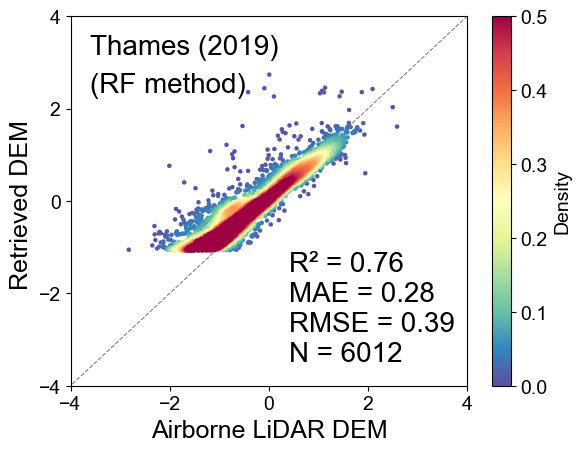

In [143]:
# validation_sample_path = f'G:\ICESat-2\Discussion5_2_new\Thames1_2019_sample_points_final.shp'
validation_sample_path = valid_path
# validation_sample_path = 'G:\ICESat-2\Discussion5_2_new\Morecambe_2023_sample_points_final.shp'
# validation_sample_path = 'G:\ICESat-2\Discussion5_2_new\wash_bay_2022_sample_points_final.shp'
output_path_ =  'G:\ICESat-2\Discussion53_new\plot\Thames_RF_plot.png'
gdf = gpd.read_file(validation_sample_path)
z = gdf.dropna()

z = z[z!=-999]
z = z[z!=6]
z = z[z!=0]
z = z.dropna()

x = z['Refer_dem']
y = z['ICE_SY5']
# y = z['DEM_random']
y = np.array(y)
x = np.array(x)

    # 以 x 为真实值，y 为预测值进行评价
R = r2_score(x, y)  # R²
MAD = np.mean(np.abs(x - y))  # Mean Absolute Deviation
MSB = np.mean(x - y)          # Mean Signed Bias
RMSE = np.sqrt(np.mean((x - y)**2))  # Root Mean Squared Error
num = len(x)
        

xy = np.vstack([x,y])  #  将两个维度的数据叠加
z = gaussian_kde(xy)(xy)  # 建立概率密度分布，并计算每个样本点的概率密度

    # Sort the points by density, so that the densest points are plotted last
idx = z.argsort()
x, y, z = x[idx], y[idx], z[idx]

fig, ax = plt.subplots()
textstr = f"R² = {R:.2f}\nMAE = {MAD:.2f}\nRMSE = {RMSE:.2f} \nN = {num}"
# textstr = f"R² = {R:.2f}\nMAE = {MAD:.2f}\nRMSE = {RMSE:.2f} \nN = 5694"
name = f'Thames (2019)'
ax.text(0.05, 0.95, name, transform = ax.transAxes, fontsize = 20, verticalalignment = 'top')
ax.text(0.05, 0.85, '(RF method)', transform = ax.transAxes, fontsize = 20, verticalalignment = 'top')
# ax.text(0.55, 0.05, textstr, transform=ax.transAxes, fontsize=18, verticalalignment='bottom', horizontalalignment='left')
ax.text(0.55, 0.05, textstr, transform=ax.transAxes, fontsize=20, verticalalignment='bottom', horizontalalignment='left')
# ax.text(0.95, 0.05, name, transform=ax.transAxes, fontsize=16, verticalalignment='bottom', horizontalalignment='right')

ax.set_xlabel('Airborne LiDAR DEM', fontsize = 18)
ax.set_ylabel('Retrieved DEM ', fontsize = 18)
ax.plot([-6, 6], [-6, 6], color='gray', linestyle='--', linewidth=0.8, zorder=1)
sc = plt.scatter(x, y, c=z, s=5, vmin=0, vmax= 0.5, cmap='Spectral_r', zorder=2)
cbar = plt.colorbar(sc)
cbar.set_label("Density", fontsize=14)       # 设置横向颜色条标题的字体大小
cbar.ax.tick_params(labelsize=14)   

ax.set_xlim(-4, 4)
ax.set_ylim(-4, 4)
ax.set_yticks(np.arange(-4, 4.1, 2))
ax.set_xticks(np.arange(-4, 4.1, 2))
ax.tick_params(axis='both', labelsize=14)
plt.savefig(output_path_, dpi=300, bbox_inches='tight')  # 保存图像

In [12]:
#-----------------------------discuss 5.1 Multii-metrics VS Frequency-only------------------------------
region = 'Region4'
method = 'MpPoly'
location = 'Morecambe'
Feature_band = 4
# year = 2019

# ICESAT_point_path = f"G:\ICESat-2\Discussion53_new\A_{location}1_30m_{year}_new10.shp"
# # ICESAT_point_path = f'G:\ICESat-2\Discussion5_2_new\{location}_random_points.shp'
# FB_raster_path = f'G:\ICESat-2\Discussion53_new\{location}_{year}_FB6_new9.tif'
# output_path =  f'G:\ICESat-2\Discussion53_new\{location}_{year}_{method}_FB6_new9.tif'

target_band = ['b1_FB6',  'b2_FB6','b3_FB6', 'b4_FB6']
target_id = [0, 1, 2, 3]
year_list = [2019, 2020, 2021, 2022, 2023, 2024]

ICESat_points_list = []
for year in year_list:
    
    FB_raster_path_ = f"G:\ICESat-2\{region}_map\{location}_map\A{year}/{location}_{year}_FB6_new9.tif"
    ICESAT_csv_path_ = f'G:\ICESat-2\{region}\{region}_{location}\A_{location}_30m_{year}_new10.csv'
    output_raw_point = f'G:\ICESat-2\{region}_map\{location}_map\A{year}\A_{location}_30m_{year}_raw_new10.shp'
    output_point = f'G:\ICESat-2\{region}_map\{location}_map\A{year}\A_{location}_30m_{year}_new10.shp'
    data = load_refer_icesat_point(FB_raster_path_, ICESAT_csv_path_, output_point, output_raw_point)

    ICESat_points_list.append(data.to_crs(epsg=4326))
    
data = pd.concat(ICESat_points_list)
y_train = data['OH'].values
x_train = data[target_band[:Feature_band]].values
print('x_train:', x_train.shape, '\n', 'y_train', y_train.shape)

if method == 'RF':
    
    best_params, classifier = optimize_random_forest(x_train, y_train)
    classifier.fit(x_train, y_train)

elif method == 'Linear':
    classifier = np.polyfit(x_train[:, 0], y_train, deg=1)
elif method == 'Poly':
    classifier = np.polyfit(x_train[:, 0], y_train, deg=2)
elif method == 'MpLinear':
    classifier = LinearRegression()
    classifier.fit(x_train, y_train)
elif method == 'MpPoly':
    degree = 3 # 设置多项式的阶数
    classifier = make_pipeline(PolynomialFeatures(degree), LinearRegression())
    classifier.fit(x_train, y_train)
else:
    print('error classifier input')
    
for year in year_list:
# Topograph mapping 

    FB_raster_path = FB_raster_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year}/{location}_{year}_FB6_new9.tif"
    output_path =  f'G:\ICESat-2\Discussion53_new\location\{location}_{year}_{method}_FB6_new9_all.tif'
    
    if not os.path.exists(FB_raster_path):
        print(FB_raster_path, ' is not exist!')
        break
    
    output_dir = os.path.dirname(output_path)
    os.makedirs(output_dir, exist_ok=True)
    
    raster = rxr.open_rasterio(FB_raster_path).values
    raster = np.nan_to_num(raster, nan = 0)
    selected_raster = raster[target_id[:Feature_band], :, :]

    if len(selected_raster.shape) != 3:
        row, col = selected_raster.shape
        selected_raster = selected_raster.reshape(1, row, col)
    else: 
        bands, row, col = selected_raster.shape

    print('selected_raster.shape', selected_raster.shape)

    k = 0
    result = np.array([[]])
    for i in range(row):
        
        x_train = np.transpose(selected_raster[:, i, :])
        if method == 'RF':
            y_pred = classifier.predict(x_train)
        elif method == 'Linear':
            y_pred = np.polyval(classifier, x_train)
        elif method == 'MpLinear':
            y_pred = classifier.predict(x_train)
        elif method == 'MpPoly':
            y_pred = classifier.predict(x_train)
        else:
            y_pred = np.polyval(classifier, x_train)
                    
        result = np.append(result, y_pred)
                    
        if i%(int(row/5)) == 0:
                        
            print(k*20 , '%_ is done')
            k = k+1
            
    result_ =  result.reshape(row, col)
    print(result.shape, type(result))
    tf_mask = raster[6,:,:]

    result_[tf_mask == 0] = 0

    save_img(output_path, FB_raster_path, result_)
    print('File output to :', output_path)

x_train: (38139, 4) 
 y_train (38139,)
selected_raster.shape (4, 2146, 1901)
0 %_ is done
20 %_ is done
40 %_ is done
60 %_ is done
80 %_ is done
100 %_ is done
(4079546,) <class 'numpy.ndarray'>
File output to : G:\ICESat-2\Discussion53_new\location\Morecambe_2019_MpPoly_FB6_new9_all.tif
selected_raster.shape (4, 2146, 1901)
0 %_ is done
20 %_ is done
40 %_ is done
60 %_ is done
80 %_ is done
100 %_ is done
(4079546,) <class 'numpy.ndarray'>
File output to : G:\ICESat-2\Discussion53_new\location\Morecambe_2020_MpPoly_FB6_new9_all.tif
selected_raster.shape (4, 2146, 1901)
0 %_ is done
20 %_ is done
40 %_ is done
60 %_ is done
80 %_ is done
100 %_ is done
(4079546,) <class 'numpy.ndarray'>
File output to : G:\ICESat-2\Discussion53_new\location\Morecambe_2021_MpPoly_FB6_new9_all.tif
selected_raster.shape (4, 2146, 1901)
0 %_ is done
20 %_ is done
40 %_ is done
60 %_ is done
80 %_ is done
100 %_ is done
(4079546,) <class 'numpy.ndarray'>
File output to : G:\ICESat-2\Discussion53_new\locat

In [15]:
# validation path 
valid_path = 'G:\ICESat-2\Discussion53_new\wash_bay_2022_sample_points_final.shp'
p = gpd.read_file(valid_path)
p.columns


Index(['Refer_dem', 'retrieved_', 'AAA', 'SY', 'DEM_new9', 'Refer_dem_',
       'DEM_new9_3', 'DEM_ICESat', 'DEM_random', 'ICE_SY', 'ICE_SY1',
       'MpLinear', 'MpPoly', 'geometry'],
      dtype='object')

In [16]:

points_path = valid_path
out_points_path = valid_path
points = gpd.read_file(valid_path)

for method in ['MpLinear', 'MpPoly']:
    
    raster_path = f'G:\ICESat-2\Discussion53_new\location\wash_bay_2019_{method}_FB6_new9_all.tif'
    with rasterio.open(raster_path) as src:
                    
        raster_crs = src.crs
        if points.crs != raster_crs:
            points = points.to_crs(raster_crs)
                    
        coords = [(geom.x, geom.y) for geom in points.geometry]
        values = list(src.sample(coords))
                    
        band_values = [val[0] for val in values]
                    
        points[f'{method}_'] = band_values
        
points.to_file(out_points_path)
points.columns

Index(['Refer_dem', 'retrieved_', 'AAA', 'SY', 'DEM_new9', 'Refer_dem_',
       'DEM_new9_3', 'DEM_ICESat', 'DEM_random', 'ICE_SY', 'ICE_SY1',
       'MpLinear', 'MpPoly', 'geometry', 'MpLinear_', 'MpPoly_'],
      dtype='object')

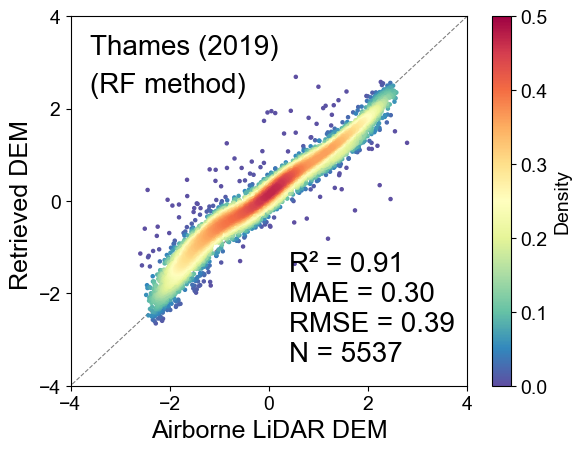

In [21]:
# validation_sample_path = f'G:\ICESat-2\Discussion5_2_new\Thames1_2019_sample_points_final.shp'
validation_sample_path = valid_path
# validation_sample_path = 'G:\ICESat-2\Discussion5_2_new\Morecambe_2023_sample_points_final.shp'
# validation_sample_path = 'G:\ICESat-2\Discussion5_2_new\\wash_bay_2022_sample_points_final.shp'
# output_path_ =  'G:\ICESat-2\Discussion53_new\plot\Thames_RF_plot.png'
gdf = gpd.read_file(validation_sample_path)
z = gdf.dropna()

z = z[z!=-999]
z = z[z!=6]
z = z[z!=0]
z = z.dropna()

x = z['Refer_dem']
y = z['MpLinear_']
# y = z['DEM_random']
y = np.array(y)
x = np.array(x)

    # 以 x 为真实值，y 为预测值进行评价
R = r2_score(x, y)  # R²
MAD = np.mean(np.abs(x - y))  # Mean Absolute Deviation
MSB = np.mean(x - y)          # Mean Signed Bias
RMSE = np.sqrt(np.mean((x - y)**2))  # Root Mean Squared Error
num = len(x)
        

xy = np.vstack([x,y])  #  将两个维度的数据叠加
z = gaussian_kde(xy)(xy)  # 建立概率密度分布，并计算每个样本点的概率密度

    # Sort the points by density, so that the densest points are plotted last
idx = z.argsort()
x, y, z = x[idx], y[idx], z[idx]

fig, ax = plt.subplots()
textstr = f"R² = {R:.2f}\nMAE = {MAD:.2f}\nRMSE = {RMSE:.2f} \nN = {num}"
# textstr = f"R² = {R:.2f}\nMAE = {MAD:.2f}\nRMSE = {RMSE:.2f} \nN = 5694"
name = f'Thames (2019)'
ax.text(0.05, 0.95, name, transform = ax.transAxes, fontsize = 20, verticalalignment = 'top')
ax.text(0.05, 0.85, '(RF method)', transform = ax.transAxes, fontsize = 20, verticalalignment = 'top')
# ax.text(0.55, 0.05, textstr, transform=ax.transAxes, fontsize=18, verticalalignment='bottom', horizontalalignment='left')
ax.text(0.55, 0.05, textstr, transform=ax.transAxes, fontsize=20, verticalalignment='bottom', horizontalalignment='left')
# ax.text(0.95, 0.05, name, transform=ax.transAxes, fontsize=16, verticalalignment='bottom', horizontalalignment='right')

ax.set_xlabel('Airborne LiDAR DEM', fontsize = 18)
ax.set_ylabel('Retrieved DEM ', fontsize = 18)
ax.plot([-6, 6], [-6, 6], color='gray', linestyle='--', linewidth=0.8, zorder=1)
sc = plt.scatter(x, y, c=z, s=5, vmin=0, vmax= 0.5, cmap='Spectral_r', zorder=2)
cbar = plt.colorbar(sc)
cbar.set_label("Density", fontsize=14)       # 设置横向颜色条标题的字体大小
cbar.ax.tick_params(labelsize=14)   

ax.set_xlim(-4, 4)
ax.set_ylim(-4, 4)
ax.set_yticks(np.arange(-4, 4.1, 2))
ax.set_xticks(np.arange(-4, 4.1, 2))
ax.tick_params(axis='both', labelsize=14)
# plt.savefig(output_path_, dpi=300, bbox_inches='tight')  # 保存图像